# 03 — Modelling & Evaluation

**Proyek:** SuperStore Business Intelligence (Tableau Public)  
**Fase CRISP-DM:** 4. Modeling → 5. Evaluation  
**Input:** `data/clean/superstore_clean.csv` dan `data/clean/customer_summary.csv` 
**Output:** `data/clean/customer_segments.csv`, dan jawaban untuk BQ3 dan BQ4

Dua model dibuat, masing-masing menjawab satu pertanyaan bisnis:

| Model | Jenis | Pertanyaan bisnis |
|---|---|---|
| A. Segmentasi pelanggan | RFM + KMeans (unsupervised) | BQ4: siapa pelanggan paling bernilai? |
| B. Prediksi transaksi rugi | Klasifikasi (supervised) | BQ3: kapan diskon membuat transaksi rugi? |

## Daftar Isi
1. Setup & Load Data
2. Model A: Segmentasi Pelanggan (RFM + KMeans)
3. Model B: Prediksi Transaksi Rugi
4. Evaluation: Jawaban untuk Pertanyaan Bisnis
5. Ringkasan dan Langkah Berikutnya

## 1. Setup & Load Data

### 1.1 Import library dan lokasi folder

In [24]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, silhouette_score, RocCurveDisplay)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

# random_state dikunci agar hasil bisa diulang
RANDOM_STATE = 42

# Cari folder root project otomatis (notebook dijalankan dari folder notebook atau root)
ROOT = next((p for p in [Path(".."), Path(".")] if (p / "data/clean/superstore_clean.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("superstore_clean.csv tidak ditemukan. Jalankan notebook 02 dulu.")

CLEAN_DIR = ROOT / "data/clean"
print("Folder root project:", ROOT.resolve())

Folder root project: C:\Github\superstore-analysis


### 1.2 Baca data bersih

In [25]:
df = pd.read_csv(
    CLEAN_DIR / "superstore_clean.csv",
    dtype={"postal_code": str},                         # kode pos tetap teks
    parse_dates=["order_date", "ship_date", "order_month_start", "first_order_date"],
)
print(f"Baris: {df.shape[0]:,} | Kolom: {df.shape[1]}")
df[["order_line_id", "customer_id", "order_date", "sales", "discount", "profit", "is_loss"]].head()

Baris: 9,993 | Kolom: 30


,order_line_id,customer_id,order_date,sales,discount,profit,is_loss
0,CA-2017-103800-01,DP-13000,2017-01-03,16.45,0.20,5.55,0
1,CA-2017-112326-01,PO-19195,2017-01-04,11.78,0.20,4.27,0
2,CA-2017-112326-02,PO-19195,2017-01-04,272.74,0.20,-64.77,1
3,CA-2017-112326-03,PO-19195,2017-01-04,3.54,0.80,-5.49,1
4,CA-2017-141817-01,MB-18085,2017-01-05,19.54,0.20,4.88,0


## 2. Model A: Segmentasi Pelanggan (RFM + KMeans)

**RFM** meringkas perilaku tiap pelanggan dengan tiga angka:
- **Recency (R):** berapa hari sejak pembelian terakhir (makin kecil makin baik).
- **Frequency (F):** berapa kali pelanggan melakukan order.
- **Monetary (M):** total Sales dari pelanggan tersebut.

**KMeans** lalu mengelompokkan pelanggan yang polanya mirip ke dalam beberapa klaster. Hasilnya diberi nama segmen yang mudah dipahami bisnis.

### 2.1 Hitung RFM

In [26]:
# Tanggal acuan = 1 hari setelah order terakhir di seluruh data (sama dengan vw_customer_summary di SQL)
ref_date = df["order_date"].max() + pd.Timedelta(days=1)
print("Tanggal acuan:", ref_date.date())

rfm = (
    df.groupby("customer_id")
    .agg(
        customer_name=("customer_name", "first"),
        last_order_date=("order_date", "max"),
        frequency=("order_id", "nunique"),     # jumlah order unik, bukan jumlah baris
        monetary=("sales", "sum"),
        total_profit=("profit", "sum"),
    )
    .reset_index()
)
rfm["recency"] = (ref_date - rfm["last_order_date"]).dt.days

rfm[["recency", "frequency", "monetary"]].describe().T

Tanggal acuan: 2020-12-31


,count,mean,std,min,25%,50%,75%,max
recency,793.00,147.92,186.39,1.00,31.00,76.00,184.00,"1,166.00"
frequency,793.00,6.32,2.55,1.00,5.00,6.00,8.00,17.00
monetary,793.00,"2,896.49","2,628.41",4.83,"1,146.05","2,256.39","3,785.28","25,043.05"


> **Cara membaca hasil:** ada 793 pelanggan. Rata-rata pelanggan terakhir membeli sekitar 148 hari lalu (median 76), melakukan sekitar 6 order, dengan total belanja sekitar 2.896 (median 2.256). Rentang Recency lebar, dari 1 sampai 1.166 hari, sehingga ada pelanggan yang sudah lama tidak aktif.

### 2.2 Cocokkan dengan hasil SQL
Angka RFM dari Python harus sama dengan `vw_customer_summary` di PostgreSQL.

In [27]:
sql_path = CLEAN_DIR / "customer_summary.csv"

if sql_path.exists():
    sql = pd.read_csv(sql_path)
    try:
        cmp = rfm.merge(
            sql[["customer_id", "recency_days", "frequency", "monetary_sales"]],
            on="customer_id", suffixes=("", "_sql"),
        )
        same = (
            len(cmp) == len(rfm)
            and (cmp["recency"] == cmp["recency_days"]).all()
            and (cmp["frequency"] == cmp["frequency_sql"]).all()
            and np.allclose(cmp["monetary"], cmp["monetary_sales"])
        )
        print(f"Pelanggan dibandingkan: {len(cmp)} | Python sama dengan SQL: {same}")
    except KeyError as e:
        print("Kolom export SQL berbeda dari yang diharapkan:", e)
else:
    print("customer_summary.csv tidak ditemukan; pemeriksaan dengan SQL dilewati.")

Pelanggan dibandingkan: 793 | Python sama dengan SQL: True


> **Cara membaca hasil:** `Python sama dengan SQL: True` artinya hitungan RFM di Python dan di PostgreSQL identik.

### 2.3 Bentuk sebaran RFM

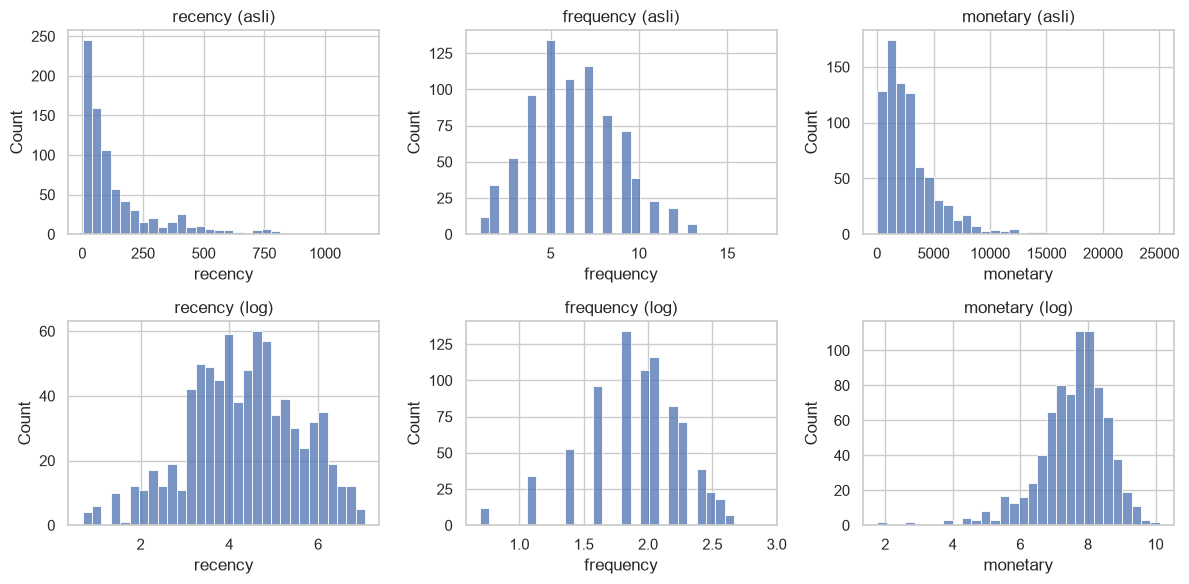

Kemiringan (skewness) sebelum dan sesudah log:


,asli,log
recency,2.27,-0.24
frequency,0.36,-0.69
monetary,2.48,-1.28


In [28]:
rfm_cols = ["recency", "frequency", "monetary"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for i, col in enumerate(rfm_cols):
    sns.histplot(rfm[col], bins=30, ax=axes[0, i])
    axes[0, i].set_title(f"{col} (asli)")
    sns.histplot(np.log1p(rfm[col]), bins=30, ax=axes[1, i])
    axes[1, i].set_title(f"{col} (log)")
plt.tight_layout()
plt.show()

print("Kemiringan (skewness) sebelum dan sesudah log:")
pd.DataFrame({"asli": rfm[rfm_cols].skew(), "log": np.log1p(rfm[rfm_cols]).skew()})

> **Cara membaca hasil:** `recency` dan `monetary` condong ke kanan (skewness positif tinggi): banyak pelanggan bernilai kecil dan sedikit pelanggan bernilai sangat besar. KMeans sensitif terhadap nilai ekstrem, jadi data ditransformasi dengan **log** sebelum diklasterkan. Tabel di bawah menunjukkan kemiringan `recency` turun dari 2,27 ke −0,24 dan `monetary` dari 2,48 ke −1,28 (masih agak miring ke kiri, tetapi jauh lebih ringan). `frequency` awalnya sudah hampir simetris (0,36), jadi log tidak banyak membantu di sana; transformasi tetap diterapkan ke ketiganya agar diperlakukan sama.

### 2.4 Transformasi dan penskalaan
KMeans mengukur jarak. Tanpa penskalaan, kolom `monetary` (ribuan) akan mendominasi `frequency` (satuan). `StandardScaler` membuat ketiganya berskala sama.

In [29]:
X_log = np.log1p(rfm[rfm_cols])            # log1p = log(1 + x), aman untuk nilai 0
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)     # tiap kolom: rata-rata 0, standar deviasi 1

print("Rata-rata setelah skala:", X_scaled.mean(axis=0).round(2))
print("Std setelah skala      :", X_scaled.std(axis=0).round(2))

Rata-rata setelah skala: [0. 0. 0.]
Std setelah skala      : [1. 1. 1.]


### 2.5 Pilih jumlah klaster (k)
Dua alat bantu: **inertia** (makin kecil makin rapat klasternya, tetapi selalu turun saat k naik) dan **silhouette** (makin dekat 1 makin terpisah klasternya).

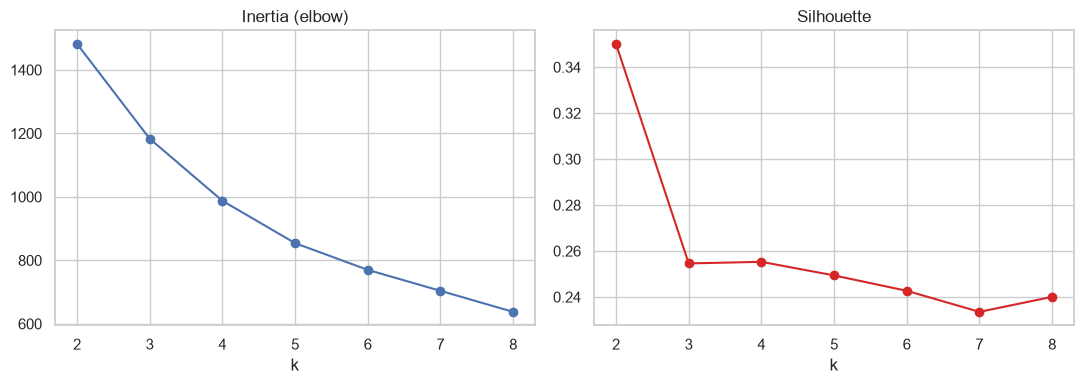

,inertia,silhouette
k,,
2,"1,481.94",0.35
3,"1,183.18",0.25
4,987.58,0.26
5,854.09,0.25
6,769.91,0.24
7,703.88,0.23
8,637.62,0.24


In [30]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    rows.append((k, km.inertia_, silhouette_score(X_scaled, km.labels_)))

k_table = pd.DataFrame(rows, columns=["k", "inertia", "silhouette"]).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_table.index, k_table["inertia"], marker="o")
axes[0].set_title("Inertia (elbow)")
axes[0].set_xlabel("k")
axes[1].plot(k_table.index, k_table["silhouette"], marker="o", color="#d62728")
axes[1].set_title("Silhouette")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

k_table

> **Cara membaca hasil:** silhouette tertinggi ada di **k = 2** (sekitar 0,35), tetapi hanya memisahkan pelanggan aktif dan tidak aktif, terlalu kasar untuk dipakai bisnis. Untuk k = 3 sampai 8, silhouette turun ke kisaran 0,23–0,26, dan kurva inertia tidak punya "siku" yang tajam. Artinya tidak ada jumlah klaster yang jelas paling benar. Kita pilih **k = 4** karena silhouette-nya setara dengan k = 3 (sekitar 0,26) dan menghasilkan empat segmen yang masing-masing punya makna bisnis yang berbeda. Ini keputusan yang dipilih untuk keterpakaian, bukan kebenaran statistik tunggal.

### 2.6 Bentuk klaster dengan k = 4

In [31]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
rfm["cluster"] = kmeans.labels_

profile = rfm.groupby("cluster").agg(
    customers=("customer_id", "size"),
    recency_mean=("recency", "mean"),
    frequency_mean=("frequency", "mean"),
    monetary_mean=("monetary", "mean"),
    sales=("monetary", "sum"),
    profit=("total_profit", "sum"),
)
profile["sales_share_%"] = profile["sales"] / profile["sales"].sum() * 100
profile["profit_share_%"] = profile["profit"] / profile["profit"].sum() * 100
profile["margin_%"] = profile["profit"] / profile["sales"] * 100
profile

,customers,recency_mean,frequency_mean,monetary_mean,sales,profit,sales_share_%,profit_share_%,margin_%
cluster,,,,,,,,,
0,199,19.72,6.78,"2,712.88","539,862.83","71,925.59",23.50,25.11,13.32
1,253,235.43,4.86,"1,936.83","490,018.46","49,699.22",21.33,17.35,10.14
2,258,103.38,8.59,"4,771.95","1,231,162.94","162,943.80",53.60,56.89,13.23
3,83,326.93,2.58,432.23,"35,875.25","1,840.48",1.56,0.64,5.13


> **Cara membaca hasil:** nomor klaster (0, 1, 2, 3) diberikan acak oleh KMeans, jadi **jangan dipakai sebagai nama**. Nama segmen ditentukan dari profilnya di langkah berikutnya.

### 2.7 Beri nama segmen berdasarkan profil
Nama ditentukan dengan aturan dari angka profil, bukan dari nomor klaster, sehingga tetap benar jika nomor berubah saat dijalankan ulang.

In [32]:
remaining = set(profile.index)
names = {}

# 1) Klaster dengan rata-rata belanja terbesar
top = profile.loc[list(remaining), "monetary_mean"].idxmax()
names[top] = "Bernilai Tinggi"; remaining.remove(top)

# 2) Dari sisanya, yang paling baru membeli
active = profile.loc[list(remaining), "recency_mean"].idxmin()
names[active] = "Aktif"; remaining.remove(active)

# 3) Dari sisanya, yang paling lama tidak membeli
lost = profile.loc[list(remaining), "recency_mean"].idxmax()
names[lost] = "Hilang"; remaining.remove(lost)

# 4) Sisanya
names[remaining.pop()] = "Berisiko"

rfm["segment_rfm"] = rfm["cluster"].map(names)

order = ["Bernilai Tinggi", "Aktif", "Berisiko", "Hilang"]
segment_summary = (
    rfm.groupby("segment_rfm")
    .agg(
        customers=("customer_id", "size"),
        recency_mean=("recency", "mean"),
        frequency_mean=("frequency", "mean"),
        monetary_mean=("monetary", "mean"),
        sales=("monetary", "sum"),
        profit=("total_profit", "sum"),
    )
    .loc[order]
)
segment_summary["customers_%"] = segment_summary["customers"] / segment_summary["customers"].sum() * 100
segment_summary["sales_share_%"] = segment_summary["sales"] / segment_summary["sales"].sum() * 100
segment_summary["profit_share_%"] = segment_summary["profit"] / segment_summary["profit"].sum() * 100
segment_summary["margin_%"] = segment_summary["profit"] / segment_summary["sales"] * 100
segment_summary

,customers,recency_mean,frequency_mean,monetary_mean,sales,profit,customers_%,sales_share_%,profit_share_%,margin_%
segment_rfm,,,,,,,,,,
Bernilai Tinggi,258,103.38,8.59,"4,771.95","1,231,162.94","162,943.80",32.53,53.60,56.89,13.23
Aktif,199,19.72,6.78,"2,712.88","539,862.83","71,925.59",25.09,23.50,25.11,13.32
Berisiko,253,235.43,4.86,"1,936.83","490,018.46","49,699.22",31.90,21.33,17.35,10.14
Hilang,83,326.93,2.58,432.23,"35,875.25","1,840.48",10.47,1.56,0.64,5.13


> **Cara membaca hasil:**
> - **Bernilai Tinggi** (258 pelanggan, sekitar 33%): belanja terbesar (rata-rata sekitar 4.772) dan paling sering order (sekitar 8,6 kali). Mereka menyumbang sekitar **54% Sales dan 57% Profit**.
> - **Aktif** (199 pelanggan): baru membeli (rata-rata 20 hari lalu) dengan belanja menengah. Sekitar 24% Sales.
> - **Berisiko** (253 pelanggan): terakhir membeli sekitar 235 hari lalu dengan frekuensi lebih rendah (sekitar 4,9 order). Sekitar 21% Sales. Ini kelompok yang paling mungkin diselamatkan.
> - **Hilang** (83 pelanggan): sekitar 327 hari tanpa pembelian, belanja kecil. Hanya sekitar 1,6% Sales dan 0,6% Profit.
>
> Margin segmen **Hilang** juga paling rendah (sekitar 5%), dibanding sekitar 13% pada segmen Bernilai Tinggi dan Aktif.

### 2.8 Visualisasi segmen

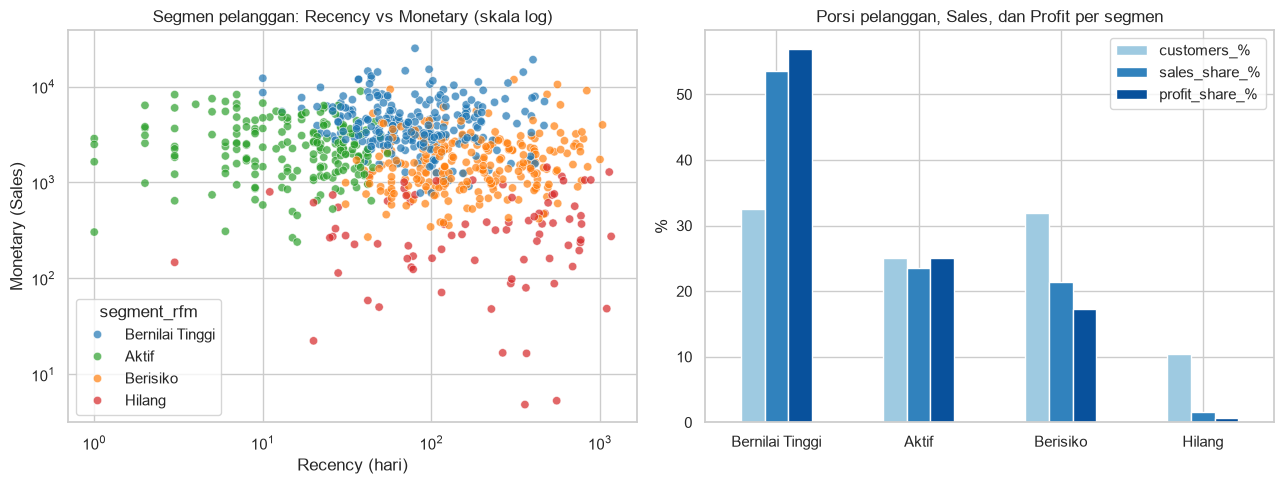

In [33]:
palette = {"Bernilai Tinggi": "#1f77b4", "Aktif": "#2ca02c", "Berisiko": "#ff7f0e", "Hilang": "#d62728"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=rfm, x="recency", y="monetary", hue="segment_rfm", hue_order=order,
    palette=palette, alpha=0.7, ax=axes[0],
)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("Segmen pelanggan: Recency vs Monetary (skala log)")
axes[0].set_xlabel("Recency (hari)"); axes[0].set_ylabel("Monetary (Sales)")

share = segment_summary[["customers_%", "sales_share_%", "profit_share_%"]]
share.plot(kind="bar", ax=axes[1], color=["#9ecae1", "#3182bd", "#08519c"])
axes[1].set_title("Porsi pelanggan, Sales, dan Profit per segmen")
axes[1].set_ylabel("%"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

> **Cara membaca hasil:** pada grafik kiri, segmen Hilang (merah) berkumpul di Recency tinggi dan belanja kecil. Pada grafik kanan, segmen Bernilai Tinggi punya porsi pelanggan sekitar 33% tetapi porsi Sales dan Profit di atas 50%, sedangkan segmen Hilang kebalikannya.

### 2.9 Simpan hasil segmentasi
File ini akan digabungkan ke data utama di Tableau memakai `customer_id`, sehingga segmen bisa dipakai sebagai filter dan warna.

In [34]:
segments_out = rfm[
    ["customer_id", "customer_name", "segment_rfm", "recency", "frequency", "monetary", "total_profit"]
].copy()
segments_out["monetary"] = segments_out["monetary"].round(2)
segments_out["total_profit"] = segments_out["total_profit"].round(2)

SEGMENTS_PATH = CLEAN_DIR / "customer_segments.csv"
segments_out.to_csv(SEGMENTS_PATH, index=False, encoding="utf-8")

print("Tersimpan:", SEGMENTS_PATH.resolve())
print(f"Baris: {len(segments_out)} | Segmen: {segments_out['segment_rfm'].nunique()}")

Tersimpan: C:\Github\superstore-analysis\data\clean\customer_segments.csv
Baris: 793 | Segmen: 4


> **Cara membaca hasil:** `Baris: 793 | Segmen: 4`. Satu baris per pelanggan.

## 3. Model B: Prediksi Transaksi Rugi

**Tujuan:** memprediksi apakah satu baris transaksi akan **rugi** (`is_loss = 1`) dari informasi yang diketahui saat transaksi terjadi, lalu melihat faktor apa yang paling menentukan. Ini menjawab BQ3 secara lebih dalam daripada tabel rata-rata di notebook 01.

### 3.1 Target dan pembanding paling sederhana

In [35]:
y = df["is_loss"]
print(f"Transaksi rugi: {y.sum():,} dari {len(y):,} ({y.mean():.1%})")
print(f"Akurasi jika selalu menebak 'tidak rugi': {1 - y.mean():.1%}")

Transaksi rugi: 1,870 dari 9,993 (18.7%)
Akurasi jika selalu menebak 'tidak rugi': 81.3%


> **Cara membaca hasil:** hanya sekitar 18,7% transaksi yang rugi. Model yang selalu menjawab "tidak rugi" sudah benar 81,3% dari waktu. Maka **akurasi saja menyesatkan**; kita juga melihat *precision*, *recall*, F1, dan ROC-AUC.
> - **Precision:** dari yang diprediksi rugi, berapa yang benar-benar rugi.
> - **Recall:** dari semua transaksi yang rugi, berapa yang berhasil terdeteksi.

### 3.2 Pilih fitur dan cegah kebocoran data
Fitur hanya berisi informasi yang tersedia **sebelum** hasil profit diketahui. Kolom turunan dari `profit` (`profit`, `profit_margin`, `is_loss`) **tidak boleh** dipakai, karena itu membocorkan jawabannya.

In [36]:
num_features = ["discount", "quantity", "sales"]
cat_features = ["category", "sub_category", "region", "segment", "ship_mode"]
features = num_features + cat_features

# Pengaman: fitur terlarang tidak boleh ikut
forbidden = {"profit", "profit_margin", "is_loss", "discount_band"}
assert not forbidden & set(features), "Ada fitur yang membocorkan target!"

X = df[features]
print("Fitur dipakai:", features)

Fitur dipakai: ['discount', 'quantity', 'sales', 'category', 'sub_category', 'region', 'segment', 'ship_mode']


> **Cara membaca hasil:** 8 fitur. `discount_band` juga dikeluarkan karena hanya turunan dari `discount` (informasinya sama).

### 3.3 Pisahkan data latih dan data uji
Pembagian dilakukan **per order** (`GroupShuffleSplit`). Baris-baris dalam satu order mirip satu sama lain; jika satu order terbelah ke data latih dan data uji, model "mengintip" jawaban dan skornya terlalu bagus.

In [37]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=df["order_id"]))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

shared_orders = set(df["order_id"].iloc[train_idx]) & set(df["order_id"].iloc[test_idx])
print(f"Data latih: {len(X_train):,} baris | Data uji: {len(X_test):,} baris")
print(f"Proporsi rugi: latih {y_train.mean():.1%} | uji {y_test.mean():.1%}")
print(f"Order yang muncul di keduanya: {len(shared_orders)}")

Data latih: 7,992 baris | Data uji: 2,001 baris
Proporsi rugi: latih 18.8% | uji 18.5%
Order yang muncul di keduanya: 0


> **Cara membaca hasil:** sekitar 8.000 baris untuk latih dan 2.000 untuk uji, dengan proporsi rugi mirip (sekitar 18–19%) dan **0 order yang terbagi**.

### 3.4 Latih model
Tiga pembanding:
1. **Aturan diskon > 20%:** tanpa model, hanya satu aturan sederhana.
2. **Logistic Regression:** model linear yang mudah dibaca.
3. **Random Forest:** kumpulan pohon keputusan yang bisa menangkap pola non-linear.

Fitur numerik diskalakan, fitur kategori diubah jadi kolom 0/1 (*one-hot*). `class_weight="balanced"` membuat model lebih memperhatikan kelas rugi yang jumlahnya lebih sedikit.

In [38]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
}

fitted = {}
for name, model in models.items():
    fitted[name] = Pipeline([("prep", preprocess), ("model", model)]).fit(X_train, y_train)
    print("Selesai dilatih:", name)

Selesai dilatih: Logistic Regression
Selesai dilatih: Random Forest


### 3.5 Evaluasi pada data uji

In [39]:
def evaluate(name, y_true, y_pred, y_score):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_score),
    }

results = []

# Pembanding 0: selalu menebak "tidak rugi"
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results.append(evaluate("Selalu 'tidak rugi'", y_test, dummy.predict(X_test), np.zeros(len(y_test))))

# Pembanding 1: aturan sederhana, rugi jika diskon di atas 20%
rule_pred = (X_test["discount"] > 0.20).astype(int)
results.append(evaluate("Aturan: diskon > 20%", y_test, rule_pred, X_test["discount"]))

# Dua model
for name, pipe in fitted.items():
    pred = pipe.predict(X_test)
    score = pipe.predict_proba(X_test)[:, 1]
    results.append(evaluate(name, y_test, pred, score))

metrics = pd.DataFrame(results).set_index("model")
metrics

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Selalu 'tidak rugi',0.82,0.00,0.00,0.00,0.50
Aturan: diskon > 20%,0.94,0.97,0.72,0.83,0.94
Logistic Regression,0.91,0.70,0.95,0.80,0.98
Random Forest,0.92,0.73,0.92,0.82,0.98


> **Cara membaca hasil:**
> - "Selalu tidak rugi": akurasi 0,815 tetapi recall 0, tidak berguna.
> - **Aturan diskon > 20%:** akurasi 0,944, precision sekitar 0,97, recall sekitar 0,72, F1 sekitar 0,83, ROC-AUC sekitar 0,94.
> - **Logistic Regression:** recall tinggi (sekitar 0,95) tetapi precision lebih rendah (sekitar 0,70), F1 sekitar 0,80, ROC-AUC sekitar 0,98.
> - **Random Forest:** F1 sekitar 0,82, ROC-AUC sekitar 0,98.
>
> **Temuan penting:** model kompleks hanya sedikit lebih baik dalam ROC-AUC (0,98 vs 0,94) dan **tidak lebih baik dalam F1** dibanding aturan satu baris. Hampir seluruh kemampuan prediksi berasal dari satu fitur: diskon.

In [40]:
# Matriks kebingungan Random Forest: baris = kenyataan, kolom = prediksi
rf_pred = fitted["Random Forest"].predict(X_test)
cm = pd.DataFrame(
    confusion_matrix(y_test, rf_pred),
    index=["Nyata: tidak rugi", "Nyata: rugi"],
    columns=["Prediksi: tidak rugi", "Prediksi: rugi"],
)
cm

,Prediksi: tidak rugi,Prediksi: rugi
Nyata: tidak rugi,1508,123
Nyata: rugi,29,341


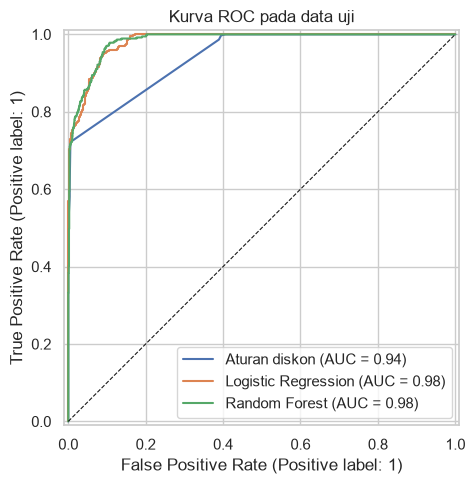

In [41]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, X_test["discount"], name="Aturan diskon", ax=ax)
for name, pipe in fitted.items():
    RocCurveDisplay.from_predictions(y_test, pipe.predict_proba(X_test)[:, 1], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax.set_title("Kurva ROC pada data uji")
plt.tight_layout()
plt.show()

> **Cara membaca hasil:** pada matriks kebingungan, kolom "Prediksi: rugi" menunjukkan sebagian kecil transaksi yang salah ditandai rugi (*false positive*) dan sebagian kecil yang lolos (*false negative*). Pada kurva ROC, makin dekat ke pojok kiri atas makin baik; ketiga garis berdekatan, sesuai temuan bahwa diskon sudah menjelaskan hampir semuanya.

### 3.6 Fitur apa yang paling berpengaruh?
*Permutation importance* mengacak satu fitur di data uji lalu melihat seberapa turun ROC-AUC. Makin besar penurunannya, makin penting fitur itu.

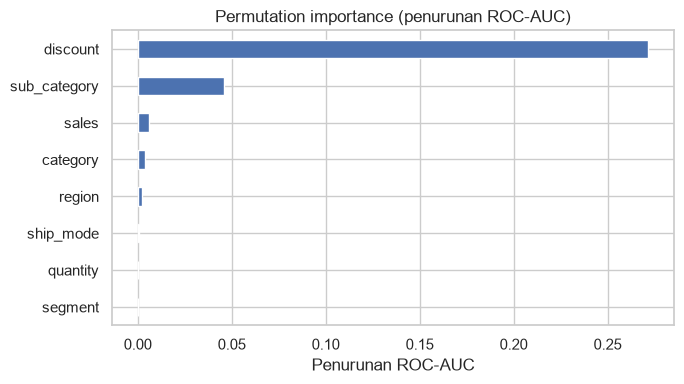

,penurunan_roc_auc
discount,0.27
sub_category,0.05
sales,0.01
category,0.00
region,0.00
ship_mode,0.00
quantity,0.00
segment,-0.00


In [42]:
perm = permutation_importance(
    fitted["Random Forest"], X_test, y_test,
    scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

ax = importance.plot(kind="barh", figsize=(7, 4), color="#4c72b0")
ax.set_title("Permutation importance (penurunan ROC-AUC)")
ax.set_xlabel("Penurunan ROC-AUC")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).to_frame("penurunan_roc_auc")

> **Cara membaca hasil:** `discount` jauh di atas semua fitur lain (penurunan ROC-AUC sekitar 0,27). `sub_category` berada di urutan kedua dengan pengaruh kecil (sekitar 0,04). `sales`, `category`, `region`, `ship_mode`, `quantity`, dan `segment` hampir tidak berpengaruh.

### 3.7 Koefisien Logistic Regression

In [43]:
lr = fitted["Logistic Regression"]
coef = pd.Series(
    lr.named_steps["model"].coef_[0],
    index=lr.named_steps["prep"].get_feature_names_out(),
).sort_values()

print("5 koefisien paling negatif (menurunkan peluang rugi):")
print(coef.head(5).round(2).to_string())
print("\n5 koefisien paling positif (menaikkan peluang rugi):")
print(coef.tail(5).iloc[::-1].round(2).to_string())

5 koefisien paling negatif (menurunkan peluang rugi):
cat__sub_category_Copiers   -2.92
cat__sub_category_Binders   -2.44
cat__sub_category_Paper     -2.29
cat__sub_category_Art       -1.97
cat__sub_category_Labels    -1.44

5 koefisien paling positif (menaikkan peluang rugi):
num__discount                   5.69
cat__sub_category_Storage       3.83
cat__sub_category_Supplies      3.60
cat__sub_category_Accessories   2.35
cat__sub_category_Fasteners     2.01


> **Cara membaca hasil:** `num__discount` adalah koefisien terbesar (sekitar +5,7), konsisten dengan permutation importance. Koefisien sub-kategori **jangan dibaca sendiri-sendiri**: nilainya dihitung setelah efek diskon dikendalikan, dan antar-kategori saling berkaitan, sehingga mudah disalahartikan. 

### 3.8 Tingkat transaksi rugi menurut diskon
Karena diskon begitu dominan, kita lihat langsung berapa persen transaksi yang rugi di tiap kelompok diskon.

In [44]:
loss_by_band = (
    df.groupby("discount_band", observed=True)
    .agg(baris=("is_loss", "size"), baris_rugi=("is_loss", "sum"), tingkat_rugi=("is_loss", "mean"))
)
loss_by_band["tingkat_rugi_%"] = loss_by_band["tingkat_rugi"] * 100
loss_by_band.drop(columns="tingkat_rugi")

,baris,baris_rugi,tingkat_rugi_%
discount_band,,,
0%,4798,0,0.00
1-20%,3803,523,13.75
21-40%,459,414,90.20
41-60%,215,215,100.00
61-80%,718,718,100.00


In [45]:
high = df[df["discount"] > 0.20]
low = df[df["discount"] <= 0.20]

print(f"Diskon > 20%: {len(high):,} baris ({len(high) / len(df):.1%} dari semua baris)")
print(f"  - tingkat rugi: {high['is_loss'].mean():.1%}")
print(f"  - total profit: {high['profit'].sum():,.0f}")
print(f"  - menyumbang {high['is_loss'].sum():,} dari {df['is_loss'].sum():,} transaksi rugi")
print(f"Diskon <= 20%: {len(low):,} baris, tingkat rugi {low['is_loss'].mean():.1%}")

Diskon > 20%: 1,392 baris (13.9% dari semua baris)
  - tingkat rugi: 96.8%
  - total profit: -135,364
  - menyumbang 1,347 dari 1,870 transaksi rugi
Diskon <= 20%: 8,601 baris, tingkat rugi 6.1%


> **Cara membaca hasil:**
> - Tanpa diskon: **0%** transaksi rugi. Diskon 1–20%: sekitar **14%**. Diskon 21–40%: sekitar **90%**. Diskon di atas 40%: **100%**.
> - Transaksi dengan diskon di atas 20% hanya 13,9% dari semua baris (1.392 baris), tetapi tingkat ruginya sekitar 97%, total profitnya sekitar **−135 ribu**, dan menyumbang 1.347 dari 1.870 transaksi rugi (sekitar 72%).
> - Transaksi dengan diskon 20% atau kurang jarang rugi (sekitar 6%). Di kelompok ini, rugi lebih sering terjadi pada Bookcases dan Tables.

### 3.9 Di mana diskon rendah tetap rugi?
Pada diskon 20% ke bawah, aturan satu baris tidak cukup, dan di sinilah fitur lain seperti sub-kategori berperan.

In [46]:
low_by_sub = (
    low.groupby("sub_category")
    .agg(baris=("is_loss", "size"), tingkat_rugi=("is_loss", "mean"))
    .assign(**{"tingkat_rugi_%": lambda t: t["tingkat_rugi"] * 100})
    .drop(columns="tingkat_rugi")
    .sort_values("tingkat_rugi_%", ascending=False)
)
low_by_sub.head(6)

,baris,tingkat_rugi_%
sub_category,,
Bookcases,158,25.32
Tables,143,21.68
Storage,846,19.03
Chairs,459,18.95
Supplies,190,17.37
Accessories,775,11.74


> **Cara membaca hasil:** pada diskon 20% ke bawah, sekitar 25% baris Bookcases dan 22% baris Tables tetap rugi, diikuti Storage dan Chairs (sekitar 19%), jauh di atas rata-rata 6%. Ini mengisyaratkan masalah profitabilitas Furniture **tidak hanya soal diskon**; kemungkinan terkait struktur biaya atau harga produk. Data biaya tidak tersedia di dataset, sehingga penyebab pastinya tidak bisa dibuktikan di sini.

## 4. Evaluation: Jawaban untuk Pertanyaan Bisnis

### 4.1 BQ3: bagaimana diskon memengaruhi profit?
- Diskon adalah penentu utama transaksi rugi. Pada diskon di atas 20%, hampir semua transaksi merugi (sekitar 97%).
- Hanya 13,9% baris yang berdiskon di atas 20%, tetapi kelompok ini membawa total profit sekitar −135 ribu dan sekitar 72% dari seluruh transaksi rugi.
- **Implikasi:** diskon di atas 20% perlu ditinjau, misalnya lewat persetujuan khusus atau batas diskon per sub-kategori.

### 4.2 BQ4: siapa pelanggan paling bernilai?
- Segmen **Bernilai Tinggi** (33% pelanggan) menyumbang sekitar 54% Sales dan 57% Profit.
- Segmen **Berisiko** (32% pelanggan, sekitar 21% Sales) adalah target utama program retensi, karena belum hilang tetapi sudah lama tidak membeli.
- Segmen **Hilang** hanya 1,6% Sales, jadi upaya pemulihannya kurang mendesak.

### 4.3 Keterbatasan
- **Korelasi, bukan sebab-akibat:** pola diskon dan kerugian tidak membuktikan bahwa menurunkan diskon otomatis menaikkan profit. Data biaya dan elastisitas permintaan tidak tersedia, jadi dampak pengurangan diskon terhadap volume penjualan tidak diketahui.
- **Model diskon nyaris deterministik:** hasil hampir sempurna menunjukkan data ini kemungkinan dibuat dengan aturan harga tertentu. Model kompleks hanya menambah sedikit di atas aturan sederhana, jadi nilainya ada pada **proses dan interpretasi**, bukan pada akurasi tinggi.
- **Segmentasi RFM bersifat subjektif:** jumlah klaster (k = 4) dipilih untuk keterpakaian bisnis, bukan karena silhouette tertinggi. Nama segmen adalah interpretasi dari profil.
- **Satu kali pembagian data:** metrik model berasal dari satu split data uji (sekitar 2.000 baris), jadi angkanya bisa bergeser sedikit jika pembagian diubah.
- **Pelanggan lama mendominasi:** 595 dari 793 pelanggan sudah ada sejak 2017, sehingga Recency mencerminkan sisa perilaku sampai akhir 2020, bukan prediksi masa depan.

## 5. Ringkasan dan Langkah Berikutnya

### 5.1 Output
| File | Fungsi |
|---|---|
| `data/clean/customer_segments.csv` | Segmen RFM per pelanggan, digabung ke Tableau lewat `customer_id` |

### 5.2 Langkah berikutnya
- [ ] **Tableau Public:** bangun dashboard dari `superstore_clean.csv`, gabungkan `customer_segments.csv`, dan cocokkan total dengan `vw_kpi_overview` di PostgreSQL.
- [ ] **README:** tulis tujuan, alur CRISP-DM, insight, screenshot dashboard, ERD, dan link Tableau Public.
- [ ] **Push** hasil akhir ke GitHub.